# Sentiment analysis — final plan

This notebook is the sentiment project. Image classification is a separate project and is not trained here.

An examiner looks for three things in every step: **what** was done, **why** that choice is fair, and **what the result was**. Each section below follows that order. The test files are scored only after a choice has been fixed on the validation split.

## Experiments

1. **Data distribution.** Token-length histograms for positive and negative tweets, on the training sample and the test set.
2. **Preprocessing impact.** The same TF-IDF + L2 logistic regression model, with cleaning changed one step at a time. This includes a stopword-removal bar.
3. **Vectorisation.** BoW, TF, IDF, TF-IDF, mean Word2Vec, and mean pretrained GloVe. The classifier stays L2 logistic regression.
4. **Algorithms and tuning on TF-IDF.** Multinomial Naive Bayes (`alpha`), L1 and L2 logistic regression (`C`), and an ANN with ReLU. The ANN is tuned on hidden size and dropout.
5. **CNN.** Kernels of width 3, 4, and 5. Dropout is tuned, then four models are compared: from scratch, batch normalisation, frozen GloVe, and fine-tuned GloVe.
6. **Pruning.** How many L1 weights become zero, and test macro F1 after magnitude pruning of the trained ANN and the best CNN.
7. **Comparison.** One table, one bar chart, and error examples for negation, mixed tweets, and odd labels.

Vectorisation is not preprocessing. Preprocessing cleans the text. Vectorisation turns the cleaned text into numbers.


## Setup

**What.** Fix the seed, the sample size, and the place results are saved.

**Why.** The same split has to feed every comparison, and the test tweets must stay out of fitting.


In [1]:
%matplotlib inline

import copy
import csv
import re
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from gensim.models import Word2Vec
from sklearn.feature_extraction.text import (
    ENGLISH_STOP_WORDS,
    CountVectorizer,
    TfidfVectorizer,
)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
)
from sklearn.naive_bayes import MultinomialNB
from sklearn.preprocessing import StandardScaler

SEED = 42
PER_CLASS = 50_000
VAL_FRACTION = 0.1
MAX_FEATURES = 20_000
NGRAM_RANGE = (1, 2)
MIN_DF = 2
C_GRID = (0.01, 0.1, 1.0, 4.0, 10.0)
REP_C_GRID = (0.1, 1.0, 4.0)
ALPHA_GRID = (0.1, 0.5, 1.0)
HIDDEN_GRID = (64, 128)
DROPOUT_GRID = (0.0, 0.2, 0.5)
ANN_EPOCHS = 4
CNN_EPOCHS = 3
CNN_TUNE_EPOCHS = 2
MAX_LEN = 40
EMBED_DIM = 100
CNN_FILTERS = 64
BATCH_ANN = 512
BATCH_CNN = 256

np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

ROOT = Path.cwd()
if not (ROOT / "sentiment_analysis.ipynb").exists() and (ROOT / "SentimentAnalysis" / "sentiment_analysis.ipynb").exists():
    ROOT = ROOT / "SentimentAnalysis"
ZIP_PATH = ROOT.parent / "Sentiment Analysis Twitter.zip"
FIG = ROOT / "results" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

_URL = re.compile(r"https?://\S+|www\.\S+", re.IGNORECASE)
_MENTION = re.compile(r"@\w+")
_HASHTAG = re.compile(r"#(\w+)")
_NON_ALPHA = re.compile(r"[^a-z\s]")
_SPACE = re.compile(r"\s+")
NEGATION = {"not", "no", "never", "nothing", "nobody", "neither", "nor", "without", "dont", "cant", "wont"}
RESULTS = []

print("Device:", device)
print("Zip:", ZIP_PATH, "exists" if ZIP_PATH.exists() else "MISSING")


Device: mps
Zip: /Users/ismailhossain/Desktop/SETU_Study/Practical Machine Learning/projects/jointProject/Sentiment Analysis Twitter.zip exists


## Shared functions

**What.** Cleaning, metrics, vectorisers, and the neural trainers live in one place.

**Why.** Every later section calls the same functions, so a difference in the table comes from the stated change.


In [2]:
def unwrap(text):
    text = text.strip()
    if len(text) >= 2 and text[0] == '"' and text[-1] == '"':
        text = text[1:-1].replace('""', '"')
    text = text.lower()
    return (
        text.replace("&amp;", " and ")
        .replace("&lt;", " ")
        .replace("&gt;", " ")
        .replace("&quot;", " ")
    )


def clean_tweet(text, urls=True, contractions=True, punct=True, drop_stops=False):
    text = unwrap(text)
    if urls:
        text = _URL.sub(" ", text)
        text = _MENTION.sub(" ", text)
        text = _HASHTAG.sub(r"\1", text)
    if contractions:
        text = text.replace("won't", "will not").replace("can't", "can not")
        text = text.replace("n't", " not ")
        text = text.replace("'m", " am ").replace("'re", " are ")
        text = text.replace("'ll", " will ").replace("'ve", " have ")
    if punct:
        text = _NON_ALPHA.sub(" ", text)
    text = _SPACE.sub(" ", text).strip()
    if drop_stops:
        text = " ".join(tok for tok in text.split() if tok not in ENGLISH_STOP_WORDS)
    return text


def load_lines(name):
    with zipfile.ZipFile(ZIP_PATH) as archive:
        raw = archive.read(name).decode("utf-8", errors="replace")
    return raw.splitlines()


def score(y_true, y_pred):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=[0, 1], zero_division=0
    )
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "precision_pos": float(precision[1]),
        "recall_pos": float(recall[1]),
        "f1_pos": float(f1[1]),
        "precision_neg": float(precision[0]),
        "recall_neg": float(recall[0]),
        "f1_neg": float(f1[0]),
    }


def remember(pipeline, group, y_true, y_pred, val_macro_f1=None, detail=""):
    row = score(y_true, y_pred)
    row.update({
        "pipeline": pipeline,
        "group": group,
        "val_macro_f1": None if val_macro_f1 is None else float(val_macro_f1),
        "detail": detail,
    })
    RESULTS.append(row)
    val_txt = "" if val_macro_f1 is None else f"  val F1 {val_macro_f1:.3f}"
    print(f"{pipeline:24}  acc {row['accuracy']:.3f}  macro F1 {row['macro_f1']:.3f}{val_txt}  {detail}")
    return row


def show_table(rows):
    header = f"{'Pipeline':24} {'Accuracy':>9} {'Macro F1':>9} {'Pos F1':>8} {'Neg F1':>8}"
    print(header)
    print("-" * len(header))
    for row in rows:
        print(
            f"{row['pipeline']:24} {row['accuracy']:9.3f} {row['macro_f1']:9.3f} "
            f"{row['f1_pos']:8.3f} {row['f1_neg']:8.3f}"
        )


def save_fig(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / name, dpi=150)
    plt.show()


def make_vectorizer(kind):
    common = dict(
        max_features=MAX_FEATURES,
        ngram_range=NGRAM_RANGE,
        min_df=MIN_DF,
        lowercase=False,
        token_pattern=r"(?u)\b[a-z]{2,}\b",
    )
    if kind == "bow":
        return CountVectorizer(**common)
    if kind == "tf":
        return TfidfVectorizer(use_idf=False, norm="l2", **common)
    if kind == "idf":
        return TfidfVectorizer(use_idf=True, binary=True, norm="l2", smooth_idf=True, **common)
    if kind == "tfidf":
        return TfidfVectorizer(use_idf=True, sublinear_tf=True, norm="l2", smooth_idf=True, **common)
    raise ValueError(kind)


def make_lr(C, penalty):
    # sklearn 1.9 uses l1_ratio: 0 is L2, 1 is L1.
    ratio = 0.0 if penalty == "l2" else 1.0
    return LogisticRegression(C=C, solver="liblinear", l1_ratio=ratio, max_iter=500)


def tune_linear(x_train, y_train, x_val, y_val, penalty, c_grid):
    curve = []
    best_c, best_f1 = c_grid[0], -1.0
    for c_value in c_grid:
        clf = make_lr(c_value, penalty)
        clf.fit(x_train, y_train)
        f1 = f1_score(y_val, clf.predict(x_val), average="macro", zero_division=0)
        curve.append((c_value, float(f1)))
        if f1 > best_f1:
            best_c, best_f1 = c_value, float(f1)
    return best_c, best_f1, curve


def mean_vectors(token_lists, lookup, dim):
    out = np.zeros((len(token_lists), dim), dtype=np.float32)
    for i, tokens in enumerate(token_lists):
        rows = [lookup[tok] for tok in tokens if tok in lookup]
        if rows:
            out[i] = np.mean(rows, axis=0)
    return out


def build_vocab(texts, max_size=20_000, min_count=2):
    counts = {}
    for text in texts:
        for tok in text.split():
            counts[tok] = counts.get(tok, 0) + 1
    ranked = sorted(((w, c) for w, c in counts.items() if c >= min_count), key=lambda item: (-item[1], item[0]))
    vocab = {"<pad>": 0, "<unk>": 1}
    for word, _ in ranked[:max_size]:
        vocab[word] = len(vocab)
    return vocab


def encode(texts, vocab):
    rows = np.zeros((len(texts), MAX_LEN), dtype=np.int64)
    for i, text in enumerate(texts):
        ids = [vocab.get(tok, 1) for tok in text.split()[:MAX_LEN]]
        if ids:
            rows[i, : len(ids)] = ids
    return rows


class TextANN(nn.Module):
    def __init__(self, n_in, hidden, dropout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_in, hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )

    def forward(self, x):
        return self.net(x).squeeze(1)


class TextCNN(nn.Module):
    def __init__(self, vocab_size, dropout, batch_norm, pretrained=None, freeze=False):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, EMBED_DIM, padding_idx=0)
        if pretrained is not None:
            with torch.no_grad():
                self.emb.weight.copy_(torch.tensor(pretrained))
                self.emb.weight[0].zero_()
        if freeze:
            self.emb.weight.requires_grad = False
        self.convs = nn.ModuleList([nn.Conv1d(EMBED_DIM, CNN_FILTERS, k) for k in (3, 4, 5)])
        self.bns = nn.ModuleList([nn.BatchNorm1d(CNN_FILTERS) for _ in range(3)]) if batch_norm else None
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(CNN_FILTERS * 3, 1)

    def forward(self, x):
        h = self.emb(x).transpose(1, 2)
        pools = []
        for i, conv in enumerate(self.convs):
            z = conv(h)
            if self.bns is not None:
                z = self.bns[i](z)
            z = torch.relu(z)
            pools.append(z.max(dim=2).values)
        return self.fc(self.drop(torch.cat(pools, dim=1))).squeeze(1)


def logits_sparse(model, matrix):
    chunks = []
    model.eval()
    with torch.no_grad():
        for start in range(0, matrix.shape[0], BATCH_ANN):
            batch = torch.tensor(matrix[start : start + BATCH_ANN].toarray(), dtype=torch.float32, device=device)
            chunks.append(model(batch).cpu())
    return torch.cat(chunks).numpy()


def train_ann(x_train, y_train, x_val, y_val, hidden, dropout, epochs, keep_best=True):
    torch.manual_seed(SEED)
    model = TextANN(x_train.shape[1], hidden, dropout).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
    loss_fn = nn.BCEWithLogitsLoss()
    y_train = y_train.astype(np.float32)
    best_state, best_f1 = None, -1.0
    for epoch in range(epochs):
        model.train()
        order = np.arange(x_train.shape[0])
        np.random.default_rng(SEED + epoch).shuffle(order)
        for start in range(0, len(order), BATCH_ANN):
            sel = order[start : start + BATCH_ANN]
            xb = torch.tensor(x_train[sel].toarray(), dtype=torch.float32, device=device)
            yb = torch.tensor(y_train[sel], dtype=torch.float32, device=device)
            opt.zero_grad()
            loss_fn(model(xb), yb).backward()
            opt.step()
        if keep_best:
            pred = (logits_sparse(model, x_val) >= 0).astype(int)
            f1 = f1_score(y_val, pred, average="macro", zero_division=0)
            if f1 > best_f1:
                best_f1 = float(f1)
                best_state = copy.deepcopy(model.state_dict())
    if keep_best:
        model.load_state_dict(best_state)
    return model, best_f1


def train_cnn(x_train, y_train, x_val, y_val, dropout, batch_norm, epochs, vocab_size, pretrained=None, freeze=False, keep_best=True):
    torch.manual_seed(SEED)
    model = TextCNN(vocab_size, dropout, batch_norm, pretrained, freeze).to(device)
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=1e-3, weight_decay=1e-4)
    loss_fn = nn.BCEWithLogitsLoss()
    xt = torch.tensor(x_train, dtype=torch.long, device=device)
    yt = torch.tensor(y_train.astype(np.float32), dtype=torch.float32, device=device)
    xv = None if x_val is None else torch.tensor(x_val, dtype=torch.long, device=device)
    best_state, best_f1 = None, -1.0
    for epoch in range(epochs):
        model.train()
        order = np.random.default_rng(SEED + epoch).permutation(xt.shape[0])
        for start in range(0, xt.shape[0], BATCH_CNN):
            sel = torch.tensor(order[start : start + BATCH_CNN], dtype=torch.long, device=device)
            opt.zero_grad()
            loss_fn(model(xt[sel]), yt[sel]).backward()
            opt.step()
        if keep_best:
            model.eval()
            with torch.no_grad():
                pred = (model(xv) >= 0).cpu().numpy().astype(int)
            f1 = f1_score(y_val, pred, average="macro", zero_division=0)
            if f1 > best_f1:
                best_f1 = float(f1)
                best_state = copy.deepcopy(model.state_dict())
    if keep_best:
        model.load_state_dict(best_state)
    return model, best_f1


def cnn_predict(model, encoded):
    model.eval()
    chunks = []
    with torch.no_grad():
        tensor = torch.tensor(encoded, dtype=torch.long, device=device)
        for start in range(0, tensor.shape[0], BATCH_CNN):
            chunks.append(model(tensor[start : start + BATCH_CNN]).cpu())
    return torch.cat(chunks).numpy()


def magnitude_prune(model, rate):
    tensors = [
        p for name, p in model.named_parameters()
        if p.ndim >= 2 and not name.startswith("emb")
    ]
    flat = torch.cat([p.detach().abs().reshape(-1) for p in tensors])
    total = int(flat.numel())
    k = int(round(rate * total))
    if k <= 0:
        return total, total
    thresh = torch.kthvalue(flat, min(k, total)).values
    kept = 0
    with torch.no_grad():
        for p in tensors:
            mask = p.abs() > thresh
            p.mul_(mask.to(p.dtype))
            kept += int(mask.sum())
    return kept, total


## 1. Data

**What.** The labels are the filenames. The training pool has 399,000 positive and 399,000 negative tweets. This notebook draws 50,000 of each at random with seed 42, holds out 10% of that sample for validation, and scores every final model on all 1,998 test tweets.

**Why.** The test files have to stay unseen. The validation split is where `C`, `alpha`, hidden size, and dropout are chosen.

**Result.** The next cell prints the counts. The cell after it plots token length. Both classes should have the same shape, so a later accuracy gap is not caused by one class being longer.


In [3]:
rng = np.random.default_rng(SEED)
train_pos = load_lines("train_Pos.en")
train_neg = load_lines("train_Neg.en")
test_pos_raw = load_lines("ttestPos.en")
test_neg_raw = load_lines("ttestNeg.en")

pos_idx = rng.choice(len(train_pos), size=PER_CLASS, replace=False)
neg_idx = rng.choice(len(train_neg), size=PER_CLASS, replace=False)
sample_raw = [train_pos[i] for i in pos_idx] + [train_neg[i] for i in neg_idx]
sample_y = np.array([1] * len(pos_idx) + [0] * len(neg_idx))
sample_clean = [clean_tweet(text) for text in sample_raw]

test_raw = test_pos_raw + test_neg_raw
test_y = np.array([1] * len(test_pos_raw) + [0] * len(test_neg_raw))
test_clean = [clean_tweet(text) for text in test_raw]

order = rng.permutation(len(sample_clean))
sample_raw = [sample_raw[i] for i in order]
sample_clean = [sample_clean[i] for i in order]
sample_y = sample_y[order]

train_parts, val_parts = [], []
for label in (0, 1):
    idx = np.flatnonzero(sample_y == label)
    rng.shuffle(idx)
    n_val = int(round(len(idx) * VAL_FRACTION))
    val_parts.append(idx[:n_val])
    train_parts.append(idx[n_val:])
train_idx = np.concatenate(train_parts)
val_idx = np.concatenate(val_parts)
rng.shuffle(train_idx)
rng.shuffle(val_idx)

train_text = [sample_clean[i] for i in train_idx]
val_text = [sample_clean[i] for i in val_idx]
y_train = sample_y[train_idx]
y_val = sample_y[val_idx]

print(f"Training pool: {len(train_pos):,} positive, {len(train_neg):,} negative")
print(f"Sample: {len(sample_clean):,}   train fold {len(train_idx):,}   validation {len(val_idx):,}")
print(f"Test: {len(test_clean):,}   positive {(test_y == 1).sum()}   negative {(test_y == 0).sum()}")
print(f"Empty after the full cleaning: sample {(np.array([t == '' for t in sample_clean])).sum()}, test {(np.array([t == '' for t in test_clean])).sum()}")


Training pool: 399,000 positive, 399,000 negative
Sample: 100,000   train fold 90,000   validation 10,000
Test: 1,998   positive 1000   negative 998
Empty after the full cleaning: sample 206, test 6


Sample tokens  mean 13.0  median 12  positive mean 12.4  negative mean 13.6
Test tokens    mean 13.0  median 12  positive mean 12.1  negative mean 13.8


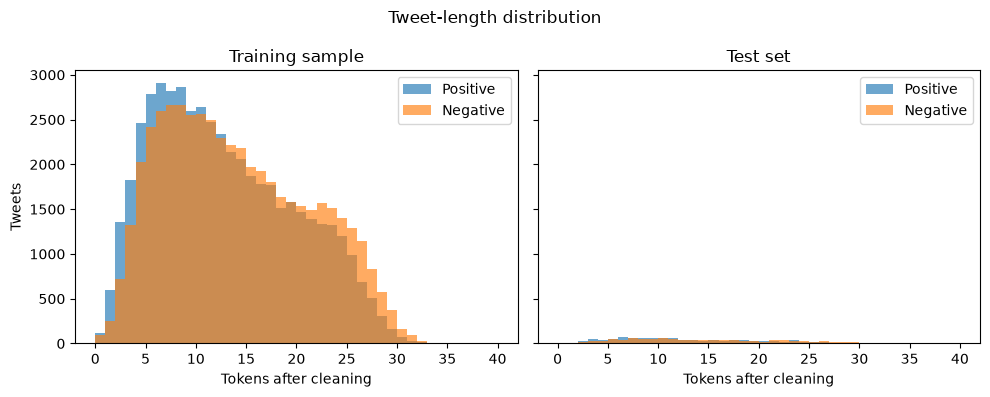

In [4]:
def token_lengths(texts):
    return np.array([0 if text == "" else len(text.split()) for text in texts])


sample_len = token_lengths(sample_clean)
test_len = token_lengths(test_clean)
print(
    f"Sample tokens  mean {sample_len.mean():.1f}  median {np.median(sample_len):.0f}  "
    f"positive mean {sample_len[sample_y == 1].mean():.1f}  negative mean {sample_len[sample_y == 0].mean():.1f}"
)
print(
    f"Test tokens    mean {test_len.mean():.1f}  median {np.median(test_len):.0f}  "
    f"positive mean {test_len[test_y == 1].mean():.1f}  negative mean {test_len[test_y == 0].mean():.1f}"
)

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, lengths, labels, title in (
    (axes[0], sample_len, sample_y, "Training sample"),
    (axes[1], test_len, test_y, "Test set"),
):
    bins = np.arange(0, 41)
    ax.hist(lengths[labels == 1], bins=bins, alpha=0.65, label="Positive")
    ax.hist(lengths[labels == 0], bins=bins, alpha=0.65, label="Negative")
    ax.set_title(title)
    ax.set_xlabel("Tokens after cleaning")
    ax.legend()
axes[0].set_ylabel("Tweets")
fig.suptitle("Tweet-length distribution")
save_fig(fig, "length_distribution.png")


## 2. Preprocessing

**What.** TF-IDF and L2 logistic regression stay fixed at `C = 1`. Only the cleaning changes: lowercase, then URL and mention removal, then contraction expansion, then punctuation removal, then the full cleaning with stopwords deleted.

**Why.** This shows which cleaning step moves the test score. Stopwords are removed in the last bar on purpose, because that also deletes `not` and `no`.

**Result.** The bar chart is the result. The last bar is the evidence for keeping negation words.


Lowercase only                test macro F1 0.799


+ URL and @mention            test macro F1 0.799


+ contractions                test macro F1 0.801


Full cleaning                 test macro F1 0.801


Full + stopwords removed      test macro F1 0.759


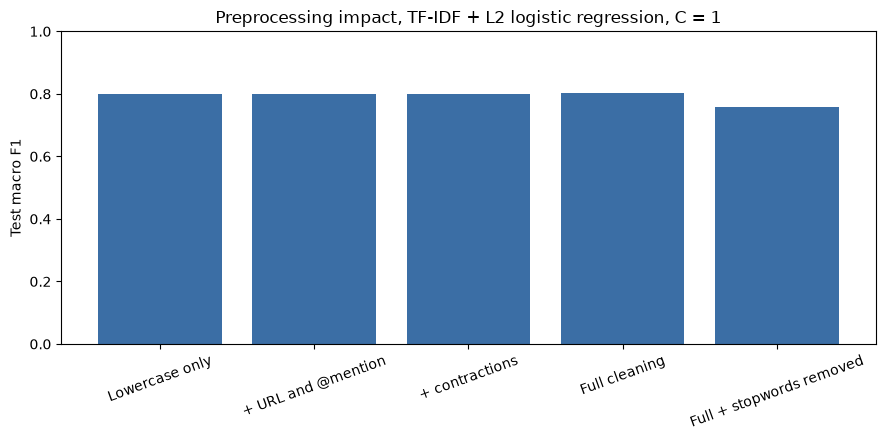

Removing stopwords changes test macro F1 by -0.043.


In [5]:
stages = [
    ("Lowercase only", dict(urls=False, contractions=False, punct=False, drop_stops=False)),
    ("+ URL and @mention", dict(urls=True, contractions=False, punct=False, drop_stops=False)),
    ("+ contractions", dict(urls=True, contractions=True, punct=False, drop_stops=False)),
    ("Full cleaning", dict(urls=True, contractions=True, punct=True, drop_stops=False)),
    ("Full + stopwords removed", dict(urls=True, contractions=True, punct=True, drop_stops=True)),
]
prep_rows = []
for name, flags in stages:
    tr = [clean_tweet(sample_raw[i], **flags) for i in train_idx]
    va = [clean_tweet(sample_raw[i], **flags) for i in val_idx]
    te = [clean_tweet(text, **flags) for text in test_raw]
    # Refit on the whole sample so the plotted score is a test score, with C fixed.
    all_text = [clean_tweet(text, **flags) for text in sample_raw]
    vec = make_vectorizer("tfidf")
    clf = make_lr(1.0, "l2")
    clf.fit(vec.fit_transform(all_text), sample_y)
    f1 = score(test_y, clf.predict(vec.transform(te)))["macro_f1"]
    prep_rows.append((name, f1))
    print(f"{name:28}  test macro F1 {f1:.3f}")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar([name for name, _ in prep_rows], [f1 for _, f1 in prep_rows], color="#3b6ea5")
ax.set_ylim(0, 1)
ax.set_ylabel("Test macro F1")
ax.set_title("Preprocessing impact, TF-IDF + L2 logistic regression, C = 1")
ax.tick_params(axis="x", rotation=20)
save_fig(fig, "preprocessing_impact.png")
full_f1 = dict(prep_rows)["Full cleaning"]
stop_f1 = dict(prep_rows)["Full + stopwords removed"]
print(f"Removing stopwords changes test macro F1 by {stop_f1 - full_f1:+.3f}.")


## 3. Vectorisation

**What.** Six representations of the same cleaned tweets, each classified with L2 logistic regression. `C` is chosen from 0.1, 1, and 4 on the validation split. Word2Vec is skip-gram, 100 dimensions, trained on this sample. GloVe is the pretrained Twitter 100-dimensional table; each tweet is the mean of its word vectors.

**Why.** The classifier is fixed, so the table isolates the representation. GloVe is the transfer-learning row: the vectors were trained elsewhere. BoW, TF, IDF, and TF-IDF are weightings of the same n-grams, not four different models.

**Result.** Read the spread among the four sparse rows, then the gap down to the two mean embeddings.


In [6]:
rep_curves = {}
vector_rows = []
PREDS = {}
for kind, label in (
    ("bow", "BoW"),
    ("tf", "TF"),
    ("idf", "IDF"),
    ("tfidf", "TF-IDF + L2"),
):
    vec = make_vectorizer(kind)
    x_tr = vec.fit_transform(train_text)
    x_va = vec.transform(val_text)
    best_c, val_f1, curve = tune_linear(x_tr, y_train, x_va, y_val, "l2", REP_C_GRID)
    rep_curves[label] = curve
    vec_f = make_vectorizer(kind)
    clf = make_lr(best_c, "l2")
    clf.fit(vec_f.fit_transform(sample_clean), sample_y)
    pred = clf.predict(vec_f.transform(test_clean))
    PREDS[label] = pred
    row = remember(label, "vectorisation", test_y, pred, val_f1, f"C={best_c}")
    vector_rows.append(row)
    if kind == "tfidf":
        TFIDF_C = best_c
        TFIDF_PRED = pred
        TFIDF_CLF_COEF = clf.coef_.ravel()


def tune_mean_embedding(train_vectors, val_vectors):
    scaler = StandardScaler()
    x_tr = scaler.fit_transform(train_vectors)
    x_va = scaler.transform(val_vectors)
    return tune_linear(x_tr, y_train, x_va, y_val, "l2", REP_C_GRID)


train_tokens = [text.split() for text in train_text]
val_tokens = [text.split() for text in val_text]
all_tokens = [text.split() for text in sample_clean]
test_tokens = [text.split() for text in test_clean]

print("Training Word2Vec on the training fold...")
w2v_tune = Word2Vec(
    sentences=train_tokens, vector_size=EMBED_DIM, window=5, min_count=2,
    sg=1, negative=5, epochs=5, seed=SEED, workers=1,
)
best_c, val_f1, w2v_curve = tune_mean_embedding(
    mean_vectors(train_tokens, w2v_tune.wv, EMBED_DIM),
    mean_vectors(val_tokens, w2v_tune.wv, EMBED_DIM),
)
print("Retraining Word2Vec on the full sample for the test score...")
w2v = Word2Vec(
    sentences=all_tokens, vector_size=EMBED_DIM, window=5, min_count=2,
    sg=1, negative=5, epochs=5, seed=SEED, workers=1,
)
scaler = StandardScaler()
x_all = scaler.fit_transform(mean_vectors(all_tokens, w2v.wv, EMBED_DIM))
x_te = scaler.transform(mean_vectors(test_tokens, w2v.wv, EMBED_DIM))
clf = make_lr(best_c, "l2")
clf.fit(x_all, sample_y)
w2v_pred = clf.predict(x_te)
PREDS["Word2Vec"] = w2v_pred
remember("Word2Vec", "vectorisation", test_y, w2v_pred, val_f1, f"C={best_c}")

print("Loading pretrained GloVe Twitter vectors...")
import gensim.downloader as api
glove = api.load("glove-twitter-100")
best_c, val_f1, glove_curve = tune_mean_embedding(
    mean_vectors(train_tokens, glove, EMBED_DIM),
    mean_vectors(val_tokens, glove, EMBED_DIM),
)
scaler = StandardScaler()
x_all = scaler.fit_transform(mean_vectors(all_tokens, glove, EMBED_DIM))
x_te = scaler.transform(mean_vectors(test_tokens, glove, EMBED_DIM))
clf = make_lr(best_c, "l2")
clf.fit(x_all, sample_y)
glove_pred = clf.predict(x_te)
PREDS["GloVe"] = glove_pred
remember("GloVe", "vectorisation", test_y, glove_pred, val_f1, f"C={best_c}, pretrained")

show_table([row for row in RESULTS if row["group"] == "vectorisation"])
sparse = [row for row in RESULTS if row["pipeline"] in {"BoW", "TF", "IDF", "TF-IDF + L2"}]
spread = max(row["macro_f1"] for row in sparse) - min(row["macro_f1"] for row in sparse)
print(f"Spread among BoW, TF, IDF, and TF-IDF: {spread:.3f} macro F1.")


BoW                       acc 0.799  macro F1 0.799  val F1 0.785  C=0.1


TF                        acc 0.800  macro F1 0.800  val F1 0.793  C=4.0


IDF                       acc 0.806  macro F1 0.806  val F1 0.792  C=1.0


TF-IDF + L2               acc 0.801  macro F1 0.801  val F1 0.790  C=1.0


Training Word2Vec on the training fold...


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


... (6 outputs left out)

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Word2Vec                  acc 0.746  macro F1 0.746  val F1 0.741  C=0.1
Loading pretrained GloVe Twitter vectors...


GloVe                     acc 0.746  macro F1 0.746  val F1 0.747  C=1.0, pretrained
Pipeline                  Accuracy  Macro F1   Pos F1   Neg F1
--------------------------------------------------------------
BoW                          0.799     0.799    0.803    0.795
TF                           0.800     0.800    0.801    0.800
IDF                          0.806     0.806    0.806    0.805
TF-IDF + L2                  0.801     0.801    0.802    0.800
Word2Vec                     0.746     0.746    0.743    0.748
GloVe                        0.746     0.746    0.745    0.747
Spread among BoW, TF, IDF, and TF-IDF: 0.007 macro F1.


## 4. Algorithms, regularisation, and tuning

**What.** The text stays TF-IDF. The models are Multinomial Naive Bayes, L1 logistic regression, L2 logistic regression, and an ANN. Naive Bayes is tuned by `alpha`. Logistic regression is tuned by `C` on a wider grid than section 3. The ANN has one ReLU hidden layer, L2 weight decay, and dropout. Hidden size and dropout are chosen on the validation split.

**Why.** Naive Bayes, L1, L2, and the ANN read the same TF-IDF matrix, so this table is the algorithm comparison. Dropout and the `C` curve are the tuning results. L1 is also the feature-pruning result, because it drives weights to zero.

**Result.** Two tuning figures, then the test scores. The L1 row reports how many of the 20,000 features survive.


Naive Bayes               acc 0.774  macro F1 0.774  val F1 0.784  alpha=0.5


TF-IDF + L2               acc 0.801  macro F1 0.801  val F1 0.790  C=1.0


TF-IDF + L1               acc 0.804  macro F1 0.804  val F1 0.791  C=1.0, nonzero weights 4555/20000


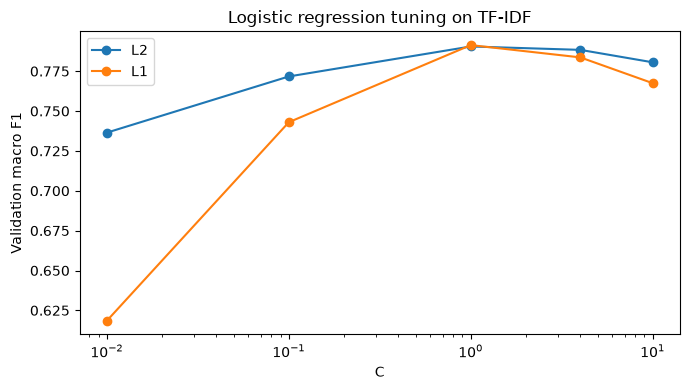

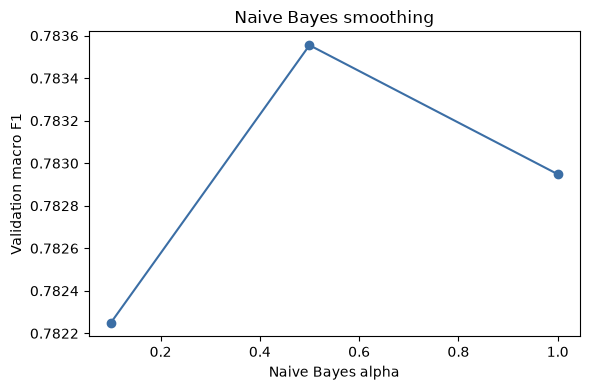

Tuning the ANN. Each run uses ReLU, dropout, and L2 weight decay.


  hidden  64  dropout 0.0  val F1 0.793


  hidden  64  dropout 0.2  val F1 0.793


  hidden  64  dropout 0.5  val F1 0.793


  hidden 128  dropout 0.0  val F1 0.790


  hidden 128  dropout 0.2  val F1 0.791


  hidden 128  dropout 0.5  val F1 0.793


ANN                       acc 0.801  macro F1 0.801  val F1 0.793  hidden=128, dropout=0.5, ReLU


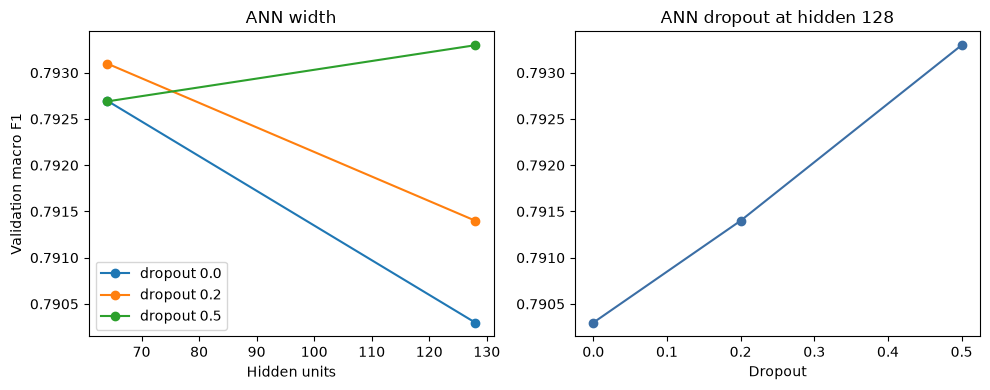

In [7]:
vec = make_vectorizer("tfidf")
x_tr = vec.fit_transform(train_text)
x_va = vec.transform(val_text)
vec_all = make_vectorizer("tfidf")
x_all = vec_all.fit_transform(sample_clean)
x_te = vec_all.transform(test_clean)

nb_curve = []
best_alpha, best_nb = ALPHA_GRID[0], -1.0
for alpha in ALPHA_GRID:
    clf = MultinomialNB(alpha=alpha)
    clf.fit(x_tr, y_train)
    f1 = f1_score(y_val, clf.predict(x_va), average="macro", zero_division=0)
    nb_curve.append((alpha, float(f1)))
    if f1 > best_nb:
        best_alpha, best_nb = alpha, float(f1)
nb = MultinomialNB(alpha=best_alpha)
nb.fit(x_all, sample_y)
NB_PRED = nb.predict(x_te)
remember("Naive Bayes", "algorithm", test_y, NB_PRED, best_nb, f"alpha={best_alpha}")

l2_c, l2_val, l2_curve = tune_linear(x_tr, y_train, x_va, y_val, "l2", C_GRID)
l1_c, l1_val, l1_curve = tune_linear(x_tr, y_train, x_va, y_val, "l1", C_GRID)
l2 = make_lr(l2_c, "l2")
l2.fit(x_all, sample_y)
L2_PRED = l2.predict(x_te)
remember("TF-IDF + L2", "algorithm", test_y, L2_PRED, l2_val, f"C={l2_c}")
l1 = make_lr(l1_c, "l1")
l1.fit(x_all, sample_y)
L1_PRED = l1.predict(x_te)
nonzero = int(np.sum(np.abs(l1.coef_) > 1e-8))
remember(
    "TF-IDF + L1",
    "algorithm",
    test_y,
    L1_PRED,
    l1_val,
    f"C={l1_c}, nonzero weights {nonzero}/{l1.coef_.size}",
)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot([c for c, _ in l2_curve], [f for _, f in l2_curve], marker="o", label="L2")
ax.plot([c for c, _ in l1_curve], [f for _, f in l1_curve], marker="o", label="L1")
ax.set_xscale("log")
ax.set_xlabel("C")
ax.set_ylabel("Validation macro F1")
ax.set_title("Logistic regression tuning on TF-IDF")
ax.legend()
save_fig(fig, "tuning_C.png")

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot([a for a, _ in nb_curve], [f for _, f in nb_curve], marker="o", color="#3b6ea5")
ax.set_xlabel("Naive Bayes alpha")
ax.set_ylabel("Validation macro F1")
ax.set_title("Naive Bayes smoothing")
save_fig(fig, "tuning_nb_alpha.png")

print("Tuning the ANN. Each run uses ReLU, dropout, and L2 weight decay.")
ann_grid = []
for hidden in HIDDEN_GRID:
    for dropout in DROPOUT_GRID:
        _, val_f1 = train_ann(x_tr, y_train, x_va, y_val, hidden, dropout, ANN_EPOCHS)
        ann_grid.append((hidden, dropout, val_f1))
        print(f"  hidden {hidden:3}  dropout {dropout:.1f}  val F1 {val_f1:.3f}")
best_hidden, best_drop, best_ann_val = max(ann_grid, key=lambda item: item[2])
ann_model, _ = train_ann(x_all, sample_y, x_va, y_val, best_hidden, best_drop, ANN_EPOCHS, keep_best=False)
ANN_LOGITS = logits_sparse(ann_model, x_te)
ANN_PRED = (ANN_LOGITS >= 0).astype(int)
remember(
    "ANN",
    "algorithm",
    test_y,
    ANN_PRED,
    best_ann_val,
    f"hidden={best_hidden}, dropout={best_drop}, ReLU",
)
ANN_MODEL = ann_model

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for dropout in DROPOUT_GRID:
    xs = [h for h, d, _ in ann_grid if d == dropout]
    ys = [f for h, d, f in ann_grid if d == dropout]
    axes[0].plot(xs, ys, marker="o", label=f"dropout {dropout}")
axes[0].set_xlabel("Hidden units")
axes[0].set_ylabel("Validation macro F1")
axes[0].legend()
axes[0].set_title("ANN width")
xs = [d for h, d, _ in ann_grid if h == best_hidden]
ys = [f for h, d, f in ann_grid if h == best_hidden]
axes[1].plot(xs, ys, marker="o", color="#3b6ea5")
axes[1].set_xlabel("Dropout")
axes[1].set_title(f"ANN dropout at hidden {best_hidden}")
save_fig(fig, "tuning_ann.png")


## 5. CNN, batch normalisation, and transfer learning

**What.** A tweet is a sequence of 100-dimensional embeddings, padded to 40 tokens. The CNN uses kernels of width 3, 4, and 5, ReLU, max-pooling, and dropout. Dropout is chosen on a from-scratch network. That dropout is then kept fixed for four test models: from scratch, batch normalisation, frozen GloVe, and fine-tuned GloVe.

**Why.** This is the model that can see a phrase such as `not bad`. Batch normalisation and GloVe are separate rows, so each change has its own result. GloVe here is transfer learning inside the network, which is different from the mean-pooled GloVe in section 3.

**Result.** The dropout figure selects the rate. The four test scores say whether order, batch norm, or pretrained vectors move macro F1.


  dropout 0.0  val F1 0.749


  dropout 0.2  val F1 0.748


  dropout 0.5  val F1 0.740


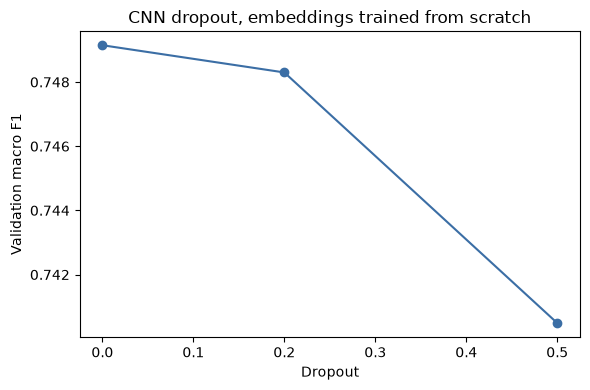

Chosen CNN dropout: 0.0


GloVe covers 19,300 of 20,000 vocabulary words.


CNN scratch               acc 0.766  macro F1 0.766  dropout=0.0


CNN + batch norm          acc 0.759  macro F1 0.759  dropout=0.0


CNN GloVe frozen          acc 0.798  macro F1 0.798  dropout=0.0


CNN GloVe fine-tuned      acc 0.799  macro F1 0.799  dropout=0.0


In [8]:
vocab_tune = build_vocab(train_text)
x_tr_cnn = encode(train_text, vocab_tune)
x_va_cnn = encode(val_text, vocab_tune)
cnn_curve = []
for dropout in DROPOUT_GRID:
    _, val_f1 = train_cnn(x_tr_cnn, y_train, x_va_cnn, y_val, dropout, False, CNN_TUNE_EPOCHS, len(vocab_tune))
    cnn_curve.append((dropout, val_f1))
    print(f"  dropout {dropout:.1f}  val F1 {val_f1:.3f}")
best_cnn_drop = max(cnn_curve, key=lambda item: item[1])[0]
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot([d for d, _ in cnn_curve], [f for _, f in cnn_curve], marker="o", color="#3b6ea5")
ax.set_xlabel("Dropout")
ax.set_ylabel("Validation macro F1")
ax.set_title("CNN dropout, embeddings trained from scratch")
save_fig(fig, "tuning_cnn_dropout.png")
print("Chosen CNN dropout:", best_cnn_drop)

vocab = build_vocab(sample_clean)
x_all_cnn = encode(sample_clean, vocab)
x_te_cnn = encode(test_clean, vocab)
weight = np.random.normal(0, 0.05, (len(vocab), EMBED_DIM)).astype(np.float32)
weight[0] = 0
covered = 0
for word, index in vocab.items():
    if word in glove:
        weight[index] = np.asarray(glove[word], dtype=np.float32)
        covered += 1
print(f"GloVe covers {covered:,} of {len(vocab) - 2:,} vocabulary words.")

cnn_specs = [
    ("CNN scratch", False, None, False),
    ("CNN + batch norm", True, None, False),
    ("CNN GloVe frozen", False, weight, True),
    ("CNN GloVe fine-tuned", False, weight, False),
]
CNN_MODELS = {}
CNN_PREDS = {}
for name, use_bn, pretrained, freeze in cnn_specs:
    model, val_f1 = train_cnn(
        x_all_cnn, sample_y, None, None, best_cnn_drop, use_bn, CNN_EPOCHS, len(vocab), pretrained, freeze, keep_best=False
    )
    logits = cnn_predict(model, x_te_cnn)
    pred = (logits >= 0).astype(int)
    remember(name, "cnn", test_y, pred, None, f"dropout={best_cnn_drop}")
    CNN_MODELS[name] = model
    CNN_PREDS[name] = pred


## 6. Pruning

**What.** L1 already removed input features in section 4. Here the trained ANN and the best CNN have their smallest convolution and linear weights set to zero at 20%, 50%, and 80%. The networks are not retrained.

**Why.** This shows how much of the fitted network the decision actually uses. It is a compression result, separate from the dropout result.

**Result.** The figure plots test macro F1 against the share of weights removed.


ANN magnitude pruning


  removed 0%  kept 2560128/2560128  test macro F1 0.801


  removed 20%  kept 2048102/2560128  test macro F1 0.800
  removed 50%  kept 1280064/2560128  test macro F1 0.802
  removed 80%  kept 512026/2560128  test macro F1 0.803
Pruning CNN GloVe fine-tuned


  removed 0%  kept 76992/76992  test macro F1 0.799
  removed 20%  kept 61594/76992  test macro F1 0.798
  removed 50%  kept 38496/76992  test macro F1 0.798
  removed 80%  kept 15398/76992  test macro F1 0.783


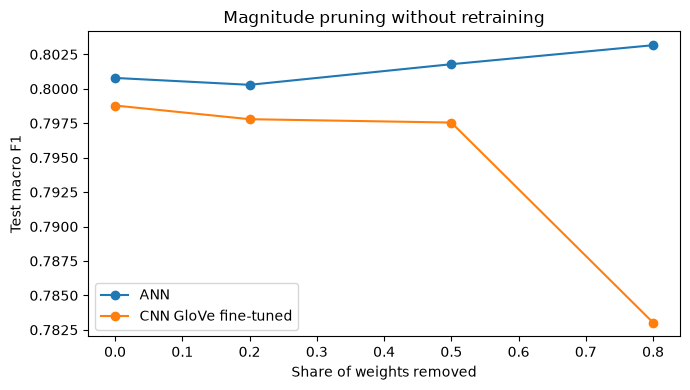

In [9]:
def prune_curve(model, predict_fn):
    base = copy.deepcopy(model.state_dict())
    rows = []
    for rate in (0.0, 0.2, 0.5, 0.8):
        model.load_state_dict(base)
        kept, total = magnitude_prune(model, rate)
        pred = (predict_fn(model) >= 0).astype(int)
        rows.append((rate, score(test_y, pred)["macro_f1"], kept, total))
        print(f"  removed {rate:.0%}  kept {kept}/{total}  test macro F1 {rows[-1][1]:.3f}")
    model.load_state_dict(base)
    return rows


print("ANN magnitude pruning")
ann_prune = prune_curve(ANN_MODEL, lambda model: logits_sparse(model, x_te))
best_cnn_name = max(
    (row for row in RESULTS if row["group"] == "cnn"),
    key=lambda row: row["macro_f1"],
)["pipeline"]
print("Pruning", best_cnn_name)
cnn_prune = prune_curve(CNN_MODELS[best_cnn_name], lambda model: cnn_predict(model, x_te_cnn))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot([r for r, _, _, _ in ann_prune], [f for _, f, _, _ in ann_prune], marker="o", label="ANN")
ax.plot([r for r, _, _, _ in cnn_prune], [f for _, f, _, _ in cnn_prune], marker="o", label=best_cnn_name)
ax.set_xlabel("Share of weights removed")
ax.set_ylabel("Test macro F1")
ax.set_title("Magnitude pruning without retraining")
ax.legend()
save_fig(fig, "pruning.png")


## 7. Comparison and errors

**What.** One table and one bar chart collect every final test score. The error examples are high-confidence mistakes of the best model, plus accuracy on tweets that contain a negation word.

**Why.** The overall F1 does not say whether the CNN fixes the phrase errors that hurt a mean embedding. Three examples are enough: a negated tweet, a mixed tweet, and a label that disagrees with the visible text.

**Result.** The bar chart is the model comparison. The printed tweets are the error analysis.


Pipeline                  Accuracy  Macro F1   Pos F1   Neg F1
--------------------------------------------------------------
BoW                          0.799     0.799    0.803    0.795
TF                           0.800     0.800    0.801    0.800
IDF                          0.806     0.806    0.806    0.805
Word2Vec                     0.746     0.746    0.743    0.748
GloVe                        0.746     0.746    0.745    0.747
Naive Bayes                  0.774     0.774    0.768    0.780
TF-IDF + L2                  0.801     0.801    0.802    0.800
TF-IDF + L1                  0.804     0.804    0.807    0.801
ANN                          0.801     0.801    0.802    0.799
CNN scratch                  0.766     0.766    0.768    0.763
CNN + batch norm             0.759     0.759    0.758    0.759
CNN GloVe frozen             0.798     0.798    0.795    0.801
CNN GloVe fine-tuned         0.799     0.799    0.797    0.800


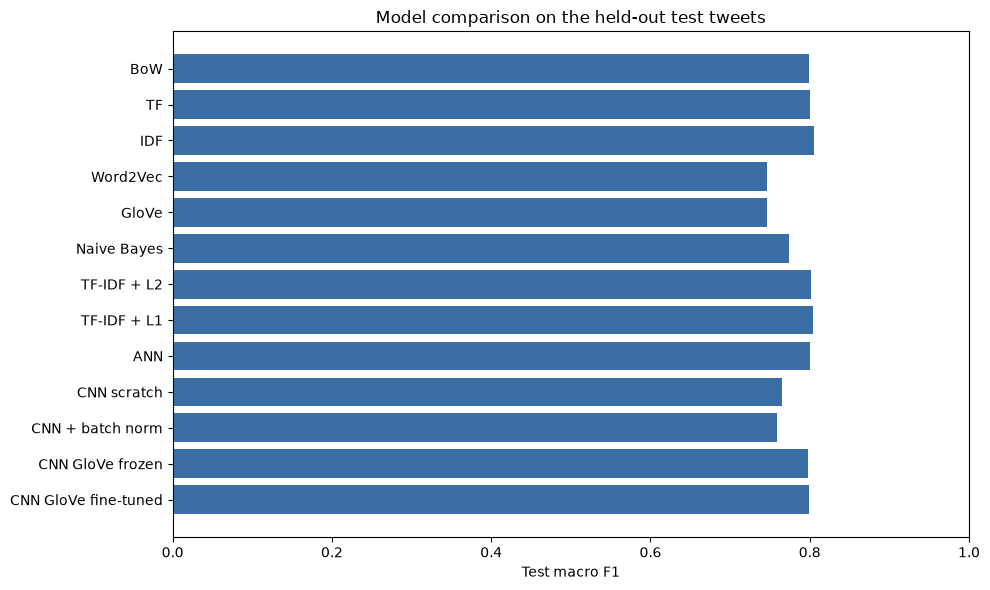

Best test macro F1: IDF 0.806

Accuracy on test tweets that contain a negation word
  tweets in this slice: 487
  BoW                       0.782
  TF                        0.797
  IDF                       0.791
  TF-IDF + L2               0.791
  Word2Vec                  0.717
  GloVe                     0.717
  Naive Bayes               0.762
  ANN                       0.795
  CNN scratch               0.745
  CNN + batch norm          0.735
  CNN GloVe frozen          0.774
  CNN GloVe fine-tuned      0.776

High-confidence false positives of IDF
 - Working until 5 then class from 6-9 the life of a college student
 - Ok to sleep I go. Can't wait to not feel like I've run 50 miles uphill.  TWUGS TWUGS TWUGS TWUGS TWUGS TWUGS TWUGS TWUGS TWUGS TWUGS
 - Vitamin D therapy for hangover  http://twitpic.com/3lizz
 - @sampan22 Haha...ooh it was gorgeous wasn't it!! And a whole weekend more to follow!! Ouch...i had blisters from my shoes yesterday
 - @aiimee_x hellen

High-confidence fal

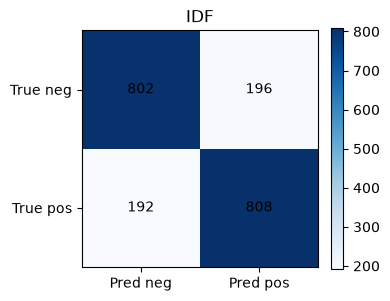

Saved /Users/ismailhossain/Desktop/SETU_Study/Practical Machine Learning/projects/jointProject/SentimentAnalysis/results/notebook_metrics.csv


In [10]:
# The section 3 TF-IDF row used a smaller C grid. Keep the section 4 score, which used the full C curve.
official = []
seen = set()
for row in RESULTS:
    if row["pipeline"] == "TF-IDF + L2" and row["group"] == "vectorisation":
        continue
    if row["pipeline"] in seen:
        continue
    seen.add(row["pipeline"])
    official.append(row)

show_table(official)
fig, ax = plt.subplots(figsize=(10, 6))
names = [row["pipeline"] for row in official]
values = [row["macro_f1"] for row in official]
ax.barh(names[::-1], values[::-1], color="#3b6ea5")
ax.set_xlabel("Test macro F1")
ax.set_xlim(0, 1)
ax.set_title("Model comparison on the held-out test tweets")
save_fig(fig, "model_comparison.png")

best = max(official, key=lambda row: row["macro_f1"])
print("Best test macro F1:", best["pipeline"], round(best["macro_f1"], 3))

pred_bank = {
    "TF-IDF + L2": L2_PRED,
    "Naive Bayes": NB_PRED,
    "ANN": ANN_PRED,
}
pred_bank.update(CNN_PREDS)

def prediction_for(pipeline):
    if pipeline in PREDS:
        return PREDS[pipeline]
    if pipeline in pred_bank:
        return pred_bank[pipeline]
    kind = {"BoW": "bow", "TF": "tf", "IDF": "idf"}[pipeline]
    vec = make_vectorizer(kind)
    x_tr = vec.fit_transform(train_text)
    x_va = vec.transform(val_text)
    chosen_c, _, _ = tune_linear(x_tr, y_train, x_va, y_val, "l2", REP_C_GRID)
    vec_f = make_vectorizer(kind)
    clf = make_lr(chosen_c, "l2")
    clf.fit(vec_f.fit_transform(sample_clean), sample_y)
    return clf.predict(vec_f.transform(test_clean))

best_pred = prediction_for(best["pipeline"])
pred_bank[best["pipeline"]] = best_pred
neural = best["pipeline"] == "ANN" or best["pipeline"] in CNN_PREDS

def contains_negation(text):
    return any(tok in NEGATION for tok in text.split())


print("\nAccuracy on test tweets that contain a negation word")
mask = np.array([contains_negation(text) for text in test_clean])
print(f"  tweets in this slice: {int(mask.sum())}")
negation_preds = {**PREDS, **pred_bank}
for name, pred in negation_preds.items():
    acc = accuracy_score(test_y[mask], pred[mask])
    print(f"  {name:24}  {acc:.3f}")

if neural:
    best_logit = ANN_LOGITS if best["pipeline"] == "ANN" else cnn_predict(CNN_MODELS[best["pipeline"]], x_te_cnn)
    fp_idx = np.flatnonzero((test_y == 0) & (best_logit >= 0))
    fn_idx = np.flatnonzero((test_y == 1) & (best_logit < 0))
    fp = fp_idx[np.argsort(best_logit[fp_idx])[::-1]][:5]
    fn = fn_idx[np.argsort(best_logit[fn_idx])][:5]
else:
    fp = np.flatnonzero((test_y == 0) & (best_pred == 1))[:5]
    fn = np.flatnonzero((test_y == 1) & (best_pred == 0))[:5]

print("\nHigh-confidence false positives of", best["pipeline"])
for i in fp:
    print(" -", test_raw[i][:220])
print("\nHigh-confidence false negatives of", best["pipeline"])
for i in fn:
    print(" -", test_raw[i][:220])

cm = confusion_matrix(test_y, best_pred, labels=[0, 1])
fig, ax = plt.subplots(figsize=(4, 4))
image = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1], ["Pred neg", "Pred pos"])
ax.set_yticks([0, 1], ["True neg", "True pos"])
ax.set_title(best["pipeline"])
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center")
fig.colorbar(image, ax=ax, fraction=0.046)
save_fig(fig, "confusion_best.png")

out = ROOT / "results" / "notebook_metrics.csv"
with out.open("w", newline="") as handle:
    writer = csv.DictWriter(
        handle,
        fieldnames=["pipeline", "group", "accuracy", "macro_f1", "precision_pos", "recall_pos", "f1_pos", "precision_neg", "recall_neg", "f1_neg", "val_macro_f1", "detail"],
    )
    writer.writeheader()
    writer.writerows(official)
print("Saved", out)
